id: notebooks/B_fourier.ipynb

explains the details of the Fourier transformation and the correlation: transform pairs and convolution theorem, van Cittert–Zernike, one baseline = one Fourier component, the dish as low-pass, cross-correlation and cross spectrum (XF vs FX), the delay beam

<!-- notebooks/B_fourier.ipynb -- theory B: Fourier transformation and correlation (Interferosim 0.9.1) -->
# B – Fourier transformation and correlation

---
  DI Erich Schubert, 07925151
  


*Theory notebook B.* Two Fourier relations carry the whole simulation chain: the **van Cittert–Zernike theorem** (the visibility is the Fourier transform of the sky – notebooks 01, 04, 06) and the **Wiener–Khinchin theorem** (the cross spectrum is the Fourier transform of the cross-correlation – notebooks 03, 05). This notebook builds both up from the one-dimensional transform, checks every statement numerically against the package, and ends with the two ways of building a correlator.

Package functions used: `SkyModel.render`, `SkyModel.visibility` (analytic visibilities), `otf_circular`, `fractional_delay`, `Accumulator` (FX), new in 0.9.1 `lag_correlation` and `xf_cross_spectrum` (XF).

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from interferosim.constants import C_LIGHT, HI_21CM
from interferosim.sky import SkyModel
from interferosim.instrument import Antenna
from interferosim.instrument.antennas import otf_circular
from interferosim.signal.correlate import fractional_delay, Accumulator, lag_correlation, xf_cross_spectrum

CFG = Path("..") / "configs"
LAM = C_LIGHT / HI_21CM
U_PROJECT = 11_500 / LAM                      # the project baseline in wavelengths at 21 cm
rng = np.random.default_rng(1)

def ft(x, dx):
    """Continuous Fourier transform of samples x (spacing dx) by FFT, centred: returns (f, X)."""
    n = x.size
    X = np.fft.fftshift(np.fft.fft(np.fft.ifftshift(x))) * dx
    f = np.fft.fftshift(np.fft.fftfreq(n, d=dx))
    return f, X
print(f"project baseline: 11.5 km = {U_PROJECT:,.0f} wavelengths at 21 cm, fringe spacing {np.degrees(1 / U_PROJECT) * 3600:.2f} arcsec")

project baseline: 11.5 km = 54,487 wavelengths at 21 cm, fringe spacing 3.79 arcsec


## 1. The Fourier transform in one dimension

$$X(f) = \int x(t)\,e^{-2\pi i f t}\,dt, \qquad x(t) = \int X(f)\,e^{+2\pi i f t}\,df .$$

Four pairs explain almost everything that follows:

| $x(t)$ | $X(f)$ | appears as |
|---|---|---|
| box of width $T$ | $T\,\mathrm{sinc}(fT)$ | band-limited receiver ↔ delay beam (section 7) |
| Gaussian of FWHM $\theta$ | Gaussian, FWHM $\propto 1/\theta$ | Gaussian source ↔ its visibility |
| shift by $t_0$ | phase ramp $e^{-2\pi i f t_0}$ | offset source ↔ visibility phase; delay ↔ phase slope over frequency |
| point (δ) | constant | point source ↔ $\lvert V\rvert$ independent of the baseline |

**Similarity:** narrow in one domain means wide in the other – small sources need long baselines. The numerical FFT (dots) reproduces the analytic transforms (lines).

box, T = 1               largest deviation FFT - analytic: 1.0e-02
Gaussian, FWHM 0.5       largest deviation FFT - analytic: 2.8e-16
Gaussian shifted by 2    largest deviation FFT - analytic: 3.2e-16


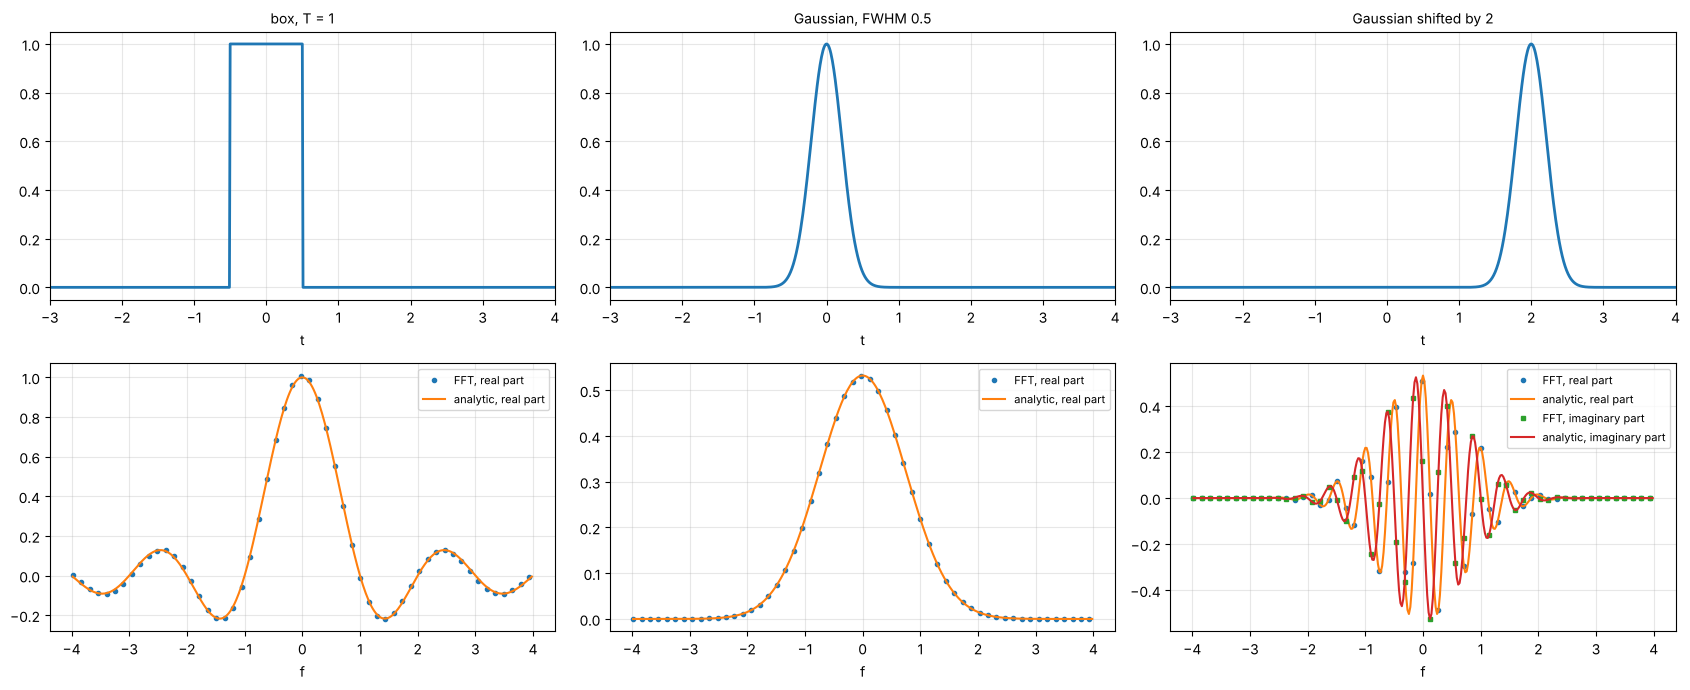

In [2]:
n, dx = 4096, 0.01
t = (np.arange(n) - n // 2) * dx
T, fw, t0 = 1.0, 0.5, 2.0
sig = fw / (2 * np.sqrt(2 * np.log(2)))
cases = [("box, T = 1", np.where(np.abs(t) <= T / 2, 1.0, 0.0), lambda f: T * np.sinc(f * T)),
         ("Gaussian, FWHM 0.5", np.exp(-0.5 * (t / sig) ** 2), lambda f: sig * np.sqrt(2 * np.pi) * np.exp(-2 * (np.pi * sig * f) ** 2)),
         ("Gaussian shifted by 2", np.exp(-0.5 * ((t - t0) / sig) ** 2),
          lambda f: sig * np.sqrt(2 * np.pi) * np.exp(-2 * (np.pi * sig * f) ** 2) * np.exp(-2j * np.pi * f * t0))]
fig, axes = plt.subplots(2, 3, figsize=(17, 7))
for k, (lab, x, Xa) in enumerate(cases):
    f, X = ft(x, dx)
    axes[0, k].plot(t, x, lw=2); axes[0, k].set(xlim=(-3, 4), xlabel="t", title=lab)
    sel = np.abs(f) < 4
    axes[1, k].plot(f[sel][::6], X.real[sel][::6], "o", ms=3, label="FFT, real part")
    axes[1, k].plot(f[sel], Xa(f[sel]).real, lw=1.5, label="analytic, real part")
    if k == 2:
        axes[1, k].plot(f[sel][::6], X.imag[sel][::6], "s", ms=3, label="FFT, imaginary part")
        axes[1, k].plot(f[sel], Xa(f[sel]).imag, lw=1.5, label="analytic, imaginary part")
    axes[1, k].set(xlabel="f"); axes[1, k].legend(fontsize=8)
    err = np.max(np.abs(X[sel] - Xa(f[sel])))
    print(f"{lab:<24s} largest deviation FFT - analytic: {err:.1e}")
for ax in axes.ravel(): ax.grid(alpha=0.3); ax.title.set_fontsize(10)
fig.tight_layout(); plt.show()

The box deviates slightly more than the Gaussians: its sharp edges fall between samples (the sampled box is not exactly of width 1). The shifted Gaussian has the same amplitude as the centred one; the shift is entirely in the **phase**, which runs linearly with $f$ – the visibility phase of an offset source (notebook 04) and the phase slope of a delay across the band (notebook 05) are both this.

## 2. The convolution theorem

$$(x * h)(t) \;\longleftrightarrow\; X(f)\,H(f).$$

A convolution in one domain is a multiplication in the other. Imaging uses it twice: the **dirty image** is the sky convolved with the dirty beam, because the measured visibilities are the true ones multiplied by the sampling function (notebook 06); the **single-dish map** is the sky convolved with the antenna pattern, because the dish multiplies the visibilities with its transfer function (section 5).

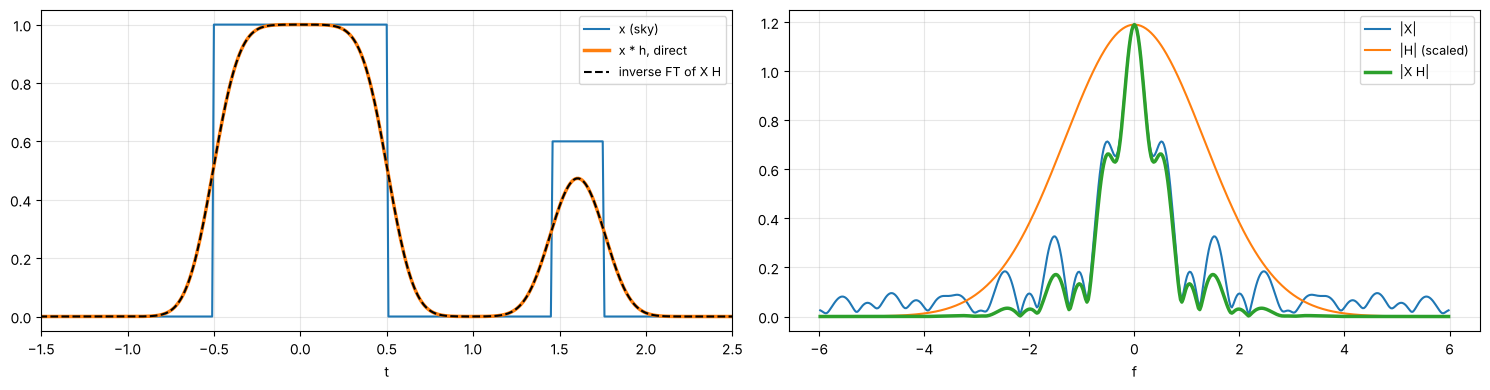

largest difference direct convolution vs product of transforms: 4.4e-16


In [3]:
x = np.where(np.abs(t) <= 0.5, 1.0, 0.0) + 0.6 * np.where(np.abs(t - 1.6) <= 0.15, 1.0, 0.0)   # a "sky"
h = np.exp(-0.5 * (t / 0.12) ** 2); h /= h.sum() * dx                                              # a "beam", area 1
direct = np.convolve(x, h, mode="full")[n // 2:n // 2 + n] * dx      # aligned with the FFT convention (centre at n//2)
_, X = ft(x, dx); f, H = ft(h, dx)
via_ft = np.real(np.fft.fftshift(np.fft.ifft(np.fft.ifftshift(X * H)))) / dx
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(t, x, lw=1.5, label="x (sky)"); axes[0].plot(t, direct, lw=2.5, label="x * h, direct")
axes[0].plot(t, via_ft, "--", lw=1.5, color="k", label="inverse FT of X H")
axes[0].set(xlim=(-1.5, 2.5), xlabel="t"); axes[0].legend(fontsize=9)
sel = np.abs(f) < 6
axes[1].plot(f[sel], np.abs(X[sel]), label="|X|"); axes[1].plot(f[sel], np.abs(H[sel]) * np.abs(X).max(), label="|H| (scaled)")
axes[1].plot(f[sel], np.abs(X[sel] * H[sel]), lw=2.5, label="|X H|"); axes[1].set(xlabel="f"); axes[1].legend(fontsize=9)
for ax in axes: ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()
print(f"largest difference direct convolution vs product of transforms: {np.max(np.abs(direct - via_ft)):.1e}")

## 3. The van Cittert–Zernike theorem

For a spatially incoherent source in the far field, the correlation of the fields at two antennas separated by $(u, v)$ wavelengths (projected) is

$$V(u,v) = \iint I(l,m)\,e^{-2\pi i (ul + vm)}\,dl\,dm ,$$

the two-dimensional Fourier transform of the brightness – the relation every visibility in this package is computed from. `SkyModel.visibility` evaluates it **analytically** per component (point: constant with phase; Gaussian: Gaussian; disc: $2J_1(x)/x$ or a Hankel transform). The check: render Cygnus A on a grid of 0.5″ pixels, transform it with a 2D FFT and compare. Along $v = 0$ the projection-slice theorem gives a sharper test: $V(u, 0)$ is the 1D transform of the brightness summed over $m$.

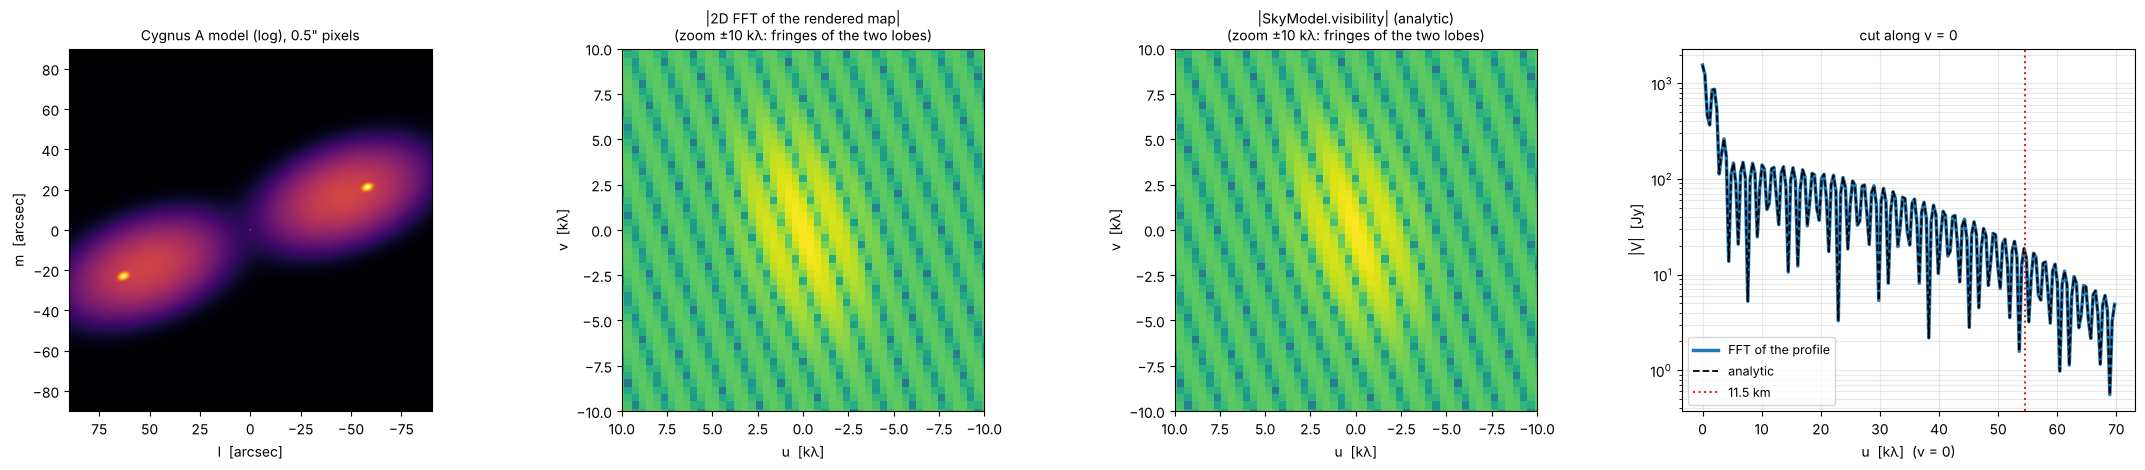

2D grid: largest deviation |FFT - analytic| = 0.00 Jy
V(0,0): FFT 1556.0 Jy, analytic 1556.0 Jy (total flux 1556 Jy)
cut along v = 0 up to 70 kλ: largest deviation 0.00 % of V(0) (the core, a point, falls on one pixel: exact; Gaussians are sampled at 0.5")


In [4]:
cyga = SkyModel.from_json(CFG / "skies" / "cyg_a.json")
npix, pix_as = 1024, 0.5                                                      # field 512", uv cell 0.4 kλ
pix = pix_as / 3600
ax_deg = (np.arange(npix) - npix // 2) * pix
img = cyga.render(ax_deg, ax_deg, pix).astype(float)
F = np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(img)))                      # sum over pixels = integral (Jy per pixel)
uax = np.fft.fftshift(np.fft.fftfreq(npix, d=np.radians(pix)))               # wavelengths
U, Vv = np.meshgrid(uax, uax)
Van = cyga.visibility(U, Vv)                                                 # same grid as the FFT
fig, axes = plt.subplots(1, 4, figsize=(22, 4.8))
axes[0].imshow(np.log10(img + 1e-3 * img.max()), origin="lower", cmap="inferno",
               extent=(ax_deg[0] * 3600, ax_deg[-1] * 3600, ax_deg[0] * 3600, ax_deg[-1] * 3600))
axes[0].set(xlim=(90, -90), ylim=(-90, 90), xlabel="l  [arcsec]", ylabel="m  [arcsec]", title=f"Cygnus A model (log), {pix_as}\" pixels")
ext = (uax[0] / 1e3, uax[-1] / 1e3, uax[0] / 1e3, uax[-1] / 1e3)
for ax, data, ttl in ((axes[1], np.abs(F), "|2D FFT of the rendered map|"),
                      (axes[2], np.abs(Van), "|SkyModel.visibility| (analytic)")):
    ax.imshow(np.log10(data + 1e-2), origin="lower", cmap="viridis", extent=ext, vmin=-1, vmax=np.log10(1600))
    ax.set(xlim=(10, -10), ylim=(-10, 10), xlabel="u  [kλ]", ylabel="v  [kλ]", title=ttl + "\n(zoom ±10 kλ: fringes of the two lobes)")
# projection-slice: V(u, 0) = 1D FT of the profile summed over m
prof = img.sum(axis=0)
u1 = np.fft.fftshift(np.fft.fftfreq(npix, d=np.radians(pix)))
V1 = np.fft.fftshift(np.fft.fft(np.fft.ifftshift(prof)))
Va1 = cyga.visibility(u1, np.zeros_like(u1))
sel = (u1 >= 0) & (u1 < 70e3)
axes[3].semilogy(u1[sel] / 1e3, np.abs(V1[sel]), lw=2.5, label="FFT of the profile")
axes[3].semilogy(u1[sel] / 1e3, np.abs(Va1[sel]), "--", color="k", lw=1.3, label="analytic")
axes[3].axvline(U_PROJECT / 1e3, color="C3", ls=":", label="11.5 km")
axes[3].set(xlabel="u  [kλ]  (v = 0)", ylabel="|V|  [Jy]", title="cut along v = 0"); axes[3].legend(fontsize=9); axes[3].grid(alpha=0.3, which="both")
for ax in axes: ax.title.set_fontsize(10)
fig.tight_layout(); plt.show()
dev = np.abs(np.abs(V1[sel]) - np.abs(Va1[sel])) / np.abs(Va1[sel]).max()
print(f"2D grid: largest deviation |FFT - analytic| = {np.abs(F - Van).max():.2f} Jy")
print(f"V(0,0): FFT {np.abs(F[npix // 2, npix // 2]):.1f} Jy, analytic {np.abs(cyga.visibility(0.0, 0.0)):.1f} Jy (total flux {cyga.total_flux_jy:.0f} Jy)")
print(f"cut along v = 0 up to 70 kλ: largest deviation {100 * dev.max():.2f} % of V(0) "
      f"(the core, a point, falls on one pixel: exact; Gaussians are sampled at {pix_as}\")")

The fine stripes in the uv-plane are the interference of the two lobes, 130″ apart (stripe spacing 1/130″ ≈ 1.6 kλ, perpendicular to the jet axis). The analytic and the numerical transform agree; the analytic route needs no grid at all, which is why the simulators never render the sky to compute visibilities.

## 4. One baseline – one Fourier component

What does a single baseline measure? Writing out the integral for one $(u, v)$: the sky is multiplied with a **cosine fringe pattern** $\cos 2\pi(ul+vm)$ and summed (real part), and with the sine pattern (imaginary part, with a minus sign). The fringe spacing on the sky is $1/\sqrt{u^2+v^2}$ radians. Structure much larger than the fringe spacing averages out – it is "resolved out"; structure at the fringe spacing gives a large $|V|$. Shown: Cygnus A with the fringes of a 2 km east–west baseline (fringe spacing 15″) – the lobes cover several fringes, the hotspots less than one.

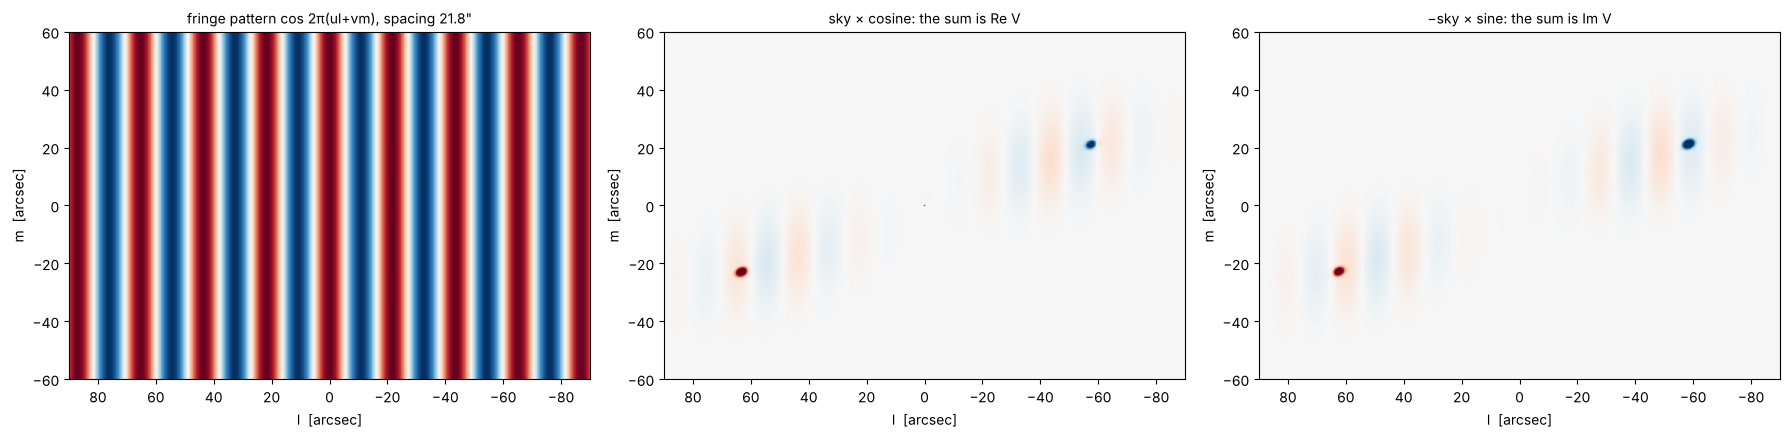

2 km east-west: sum over the map  V =     22.1    -23.2i Jy
                analytic         V =     22.1    -23.2i Jy   (|V| = 32.0 of 1556 Jy)


In [5]:
u0, v0 = 2000 / LAM, 0.0
L, M = np.meshgrid(np.radians(ax_deg), np.radians(ax_deg))
cosp, sinp = np.cos(2 * np.pi * (u0 * L + v0 * M)), np.sin(2 * np.pi * (u0 * L + v0 * M))
re_num, im_num = np.sum(img * cosp), -np.sum(img * sinp)
Va = cyga.visibility(u0, v0)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
e = (ax_deg[0] * 3600, ax_deg[-1] * 3600, ax_deg[0] * 3600, ax_deg[-1] * 3600)
axes[0].imshow(cosp, origin="lower", cmap="RdBu_r", extent=e); axes[0].set_title(f"fringe pattern cos 2π(ul+vm), spacing {np.degrees(1 / u0) * 3600:.1f}\"")
axes[1].imshow(img * cosp, origin="lower", cmap="RdBu_r", extent=e, vmin=-img.max() * 0.3, vmax=img.max() * 0.3)
axes[1].set_title("sky × cosine: the sum is Re V")
axes[2].imshow(-img * sinp, origin="lower", cmap="RdBu_r", extent=e, vmin=-img.max() * 0.3, vmax=img.max() * 0.3)
axes[2].set_title("−sky × sine: the sum is Im V")
for ax in axes: ax.set(xlim=(90, -90), ylim=(-60, 60), xlabel="l  [arcsec]", ylabel="m  [arcsec]"); ax.title.set_fontsize(10)
fig.tight_layout(); plt.show()
print(f"2 km east-west: sum over the map  V = {re_num:8.1f} {im_num:+8.1f}i Jy")
print(f"                analytic         V = {Va.real:8.1f} {Va.imag:+8.1f}i Jy   (|V| = {abs(Va):.1f} of {cyga.total_flux_jy:.0f} Jy)")

## 5. Visibility over the baseline – and the dish as a low-pass filter

Along one direction of the uv-plane, $|V(q)|$ tells how much flux shows structure on the scale $1/q$. The known sources of notebook 01 fall off at very different baselines; at 54.5 kλ (11.5 km) only compact components survive.

A **single dish** of diameter $D$ is an interferometer of all the baseline pairs within its aperture: its transfer function is the **autocorrelation of the aperture**, which for a uniformly illuminated disc is `otf_circular` – non-zero only for $q < D/\lambda$. Right: the autocorrelation of a sampled 3 m disc computed with the convolution theorem (FFT, $|\cdot|^2$, inverse FFT) against the formula.

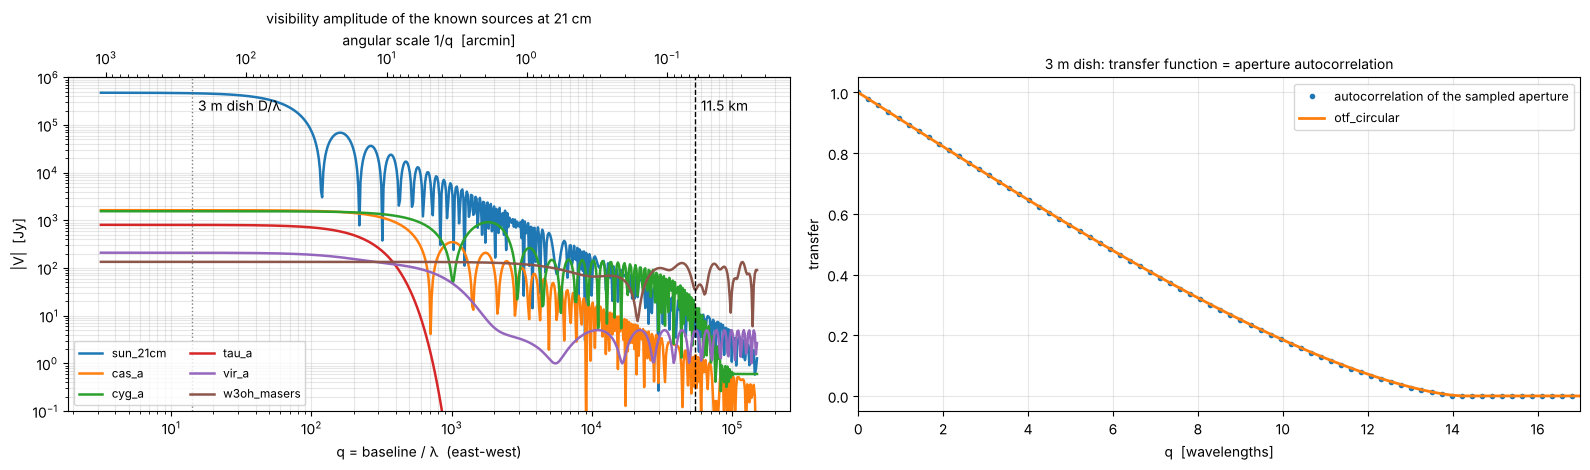

dish: transfer at half the cut-off 0.390 (formula 0.391); cut-off D/λ = 14.2 λ, the project baseline is 3,833 times longer


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
q = np.logspace(0.5, np.log10(1.5e5), 600)
for name in ("sun_21cm", "cas_a", "cyg_a", "tau_a", "vir_a", "w3oh_masers"):
    s = SkyModel.from_json(CFG / "skies" / f"{name}.json")
    axes[0].loglog(q, np.abs(s.visibility(q, np.zeros_like(q))) + 1e-3, lw=1.8, label=name)
axes[0].axvline(U_PROJECT, color="k", ls="--", lw=1); axes[0].annotate("11.5 km", (U_PROJECT, 2e5), xytext=(4, 0), textcoords="offset points")
axes[0].axvline(3.0 / LAM, color="0.5", ls=":", lw=1); axes[0].annotate("3 m dish D/λ", (3 / LAM, 2e5), xytext=(4, 0), textcoords="offset points")
axes[0].set(xlabel="q = baseline / λ  (east-west)", ylabel="|V|  [Jy]", ylim=(1e-1, 1e6), title="visibility amplitude of the known sources at 21 cm")
axes[0].legend(fontsize=8.5, ncol=2); axes[0].grid(alpha=0.3, which="both")
sec = axes[0].secondary_xaxis("top", functions=(lambda x: np.degrees(1 / np.maximum(x, 1e-9)) * 60, lambda a: 1 / np.radians(np.maximum(a, 1e-9) / 60)))
sec.set_xlabel("angular scale 1/q  [arcmin]")
# aperture autocorrelation
N, dxm = 512, 0.05                                   # 25.6 m grid, 5 cm cells
xa = (np.arange(N) - N // 2) * dxm
XA, YA = np.meshgrid(xa, xa)
A = (np.hypot(XA, YA) <= 1.5).astype(float)          # 3 m disc
ac = np.real(np.fft.fftshift(np.fft.ifft2(np.abs(np.fft.fft2(A)) ** 2)))
ac /= ac.max()
sep = xa[N // 2:]                                    # separation in metres
axes[1].plot(sep / LAM, ac[N // 2, N // 2:], "o", ms=3, label="autocorrelation of the sampled aperture")
axes[1].plot(sep / LAM, otf_circular(sep / LAM, 3.0 / LAM), lw=2, label="otf_circular")
axes[1].set(xlim=(0, 17), xlabel="q  [wavelengths]", ylabel="transfer", title="3 m dish: transfer function = aperture autocorrelation")
axes[1].legend(fontsize=9); axes[1].grid(alpha=0.3)
for ax in axes: ax.title.set_fontsize(10)
fig.tight_layout(); plt.show()
i = np.argmin(np.abs(sep / LAM - 0.5 * 3 / LAM))
print(f"dish: transfer at half the cut-off {ac[N // 2, N // 2 + i]:.3f} (formula {otf_circular(0.5 * 3 / LAM, 3 / LAM):.3f}); "
      f"cut-off D/λ = {3 / LAM:.1f} λ, the project baseline is {U_PROJECT / (3 / LAM):,.0f} times longer")

## 6. Correlation and cross spectrum: XF and FX

The correlator multiplies the two station signals. The **cross-correlation function** over the lag $\tau$ and the **cross spectrum** are a Fourier pair (Wiener–Khinchin):

$$R_{ab}(\tau) = \langle a(t+\tau)\,b^*(t)\rangle \;\longleftrightarrow\; S_{ab}(f) = \langle A(f)\,B^*(f)\rangle .$$

Two ways to build a correlator follow:

* **XF** (correlate, then Fourier transform): multiply for every lag, average, transform the lags into channels – the classical hardware correlator;
* **FX** (Fourier transform, then multiply): transform blocks of $N$ samples of each station, multiply channel by channel, average – the correlator of notebook 05 (`Accumulator`).

Test signal: a common noise signal of power 1 received by both stations, station b delayed by 3.4 samples (`fractional_delay`), plus independent receiver noise of the same power – correlated power 1 of a total power 2 per station, correlation coefficient 0.5. The lag function peaks near −3.4 samples (between the lags −3 and −4); in the cross spectrum the delay appears as the **phase slope** $2\pi f\tau$ – which resolves the fraction of a sample.

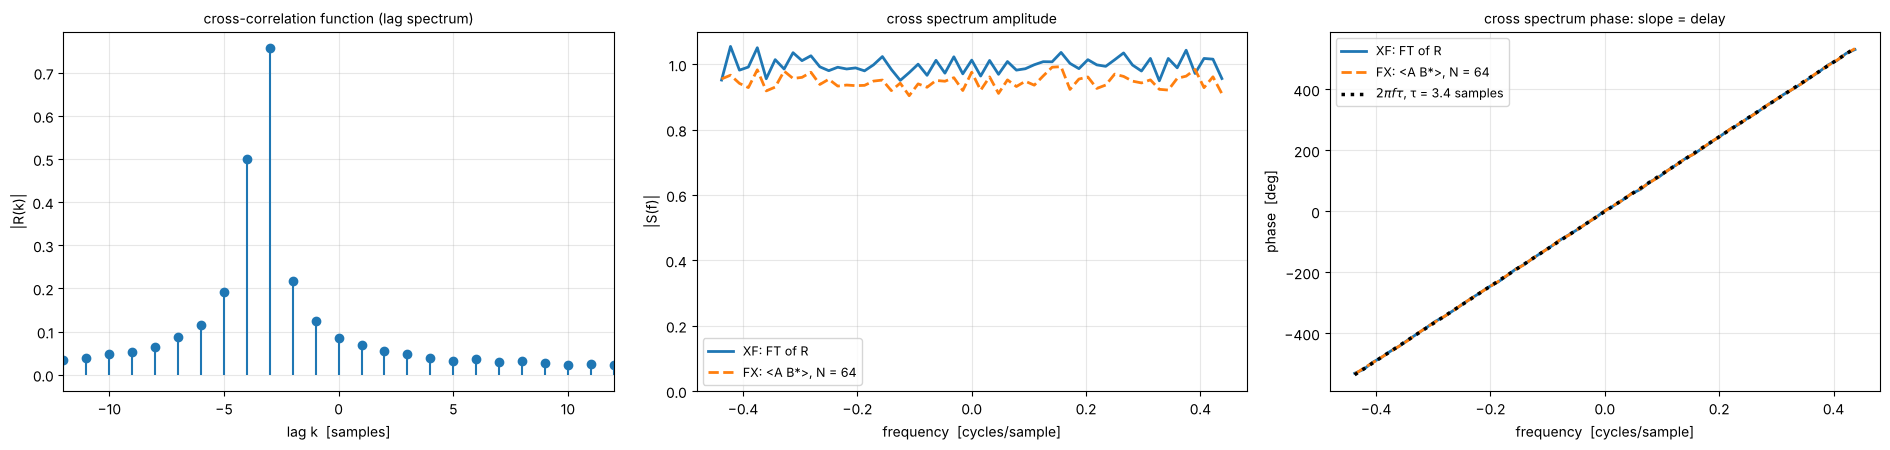

XF: mean |S| 0.992, delay from the phase slope 3.395 samples
FX: mean |S| 0.939, delay from the phase slope 3.397 samples
lag spectrum: peak at k = -3 (integer lags only); true delay of b: 3.4 samples


In [7]:
n, d, nlag = 2 ** 18, 3.4, 64
s = (rng.standard_normal(n) + 1j * rng.standard_normal(n)) / np.sqrt(2)
a = s + (rng.standard_normal(n) + 1j * rng.standard_normal(n)) / np.sqrt(2)
b = fractional_delay(s, d) + (rng.standard_normal(n) + 1j * rng.standard_normal(n)) / np.sqrt(2)
lags, R = lag_correlation(a, b, nlag)
S_xf = xf_cross_spectrum(a, b, nlag)
acc = Accumulator.create(nlag, "rect"); acc.add(a, b)
S_fx = acc.visibility() / acc.window_power
f = np.fft.fftshift(np.fft.fftfreq(nlag))                  # cycles per sample
inner = np.abs(f) < 0.45                                   # band edges excluded (fractional delay near Nyquist)

def phase_deg(S):
    p = np.unwrap(np.angle(S[inner]))
    return np.degrees(p - 2 * np.pi * np.round(p[np.argmin(np.abs(f[inner]))] / (2 * np.pi)))
fig, axes = plt.subplots(1, 3, figsize=(19, 4.6))
axes[0].stem(lags, np.abs(R), basefmt=" "); axes[0].set(xlim=(-12, 12), xlabel="lag k  [samples]", ylabel="|R(k)|",
                                                       title="cross-correlation function (lag spectrum)")
for S, lab, st in ((S_xf, "XF: FT of R", "-"), (S_fx, "FX: <A B*>, N = 64", "--")):
    axes[1].plot(f[inner], np.abs(S[inner]), st, lw=2, label=lab)
    axes[2].plot(f[inner], phase_deg(S), st, lw=2, label=lab)
axes[2].plot(f[inner], np.degrees(2 * np.pi * f[inner] * d), ":", color="k", lw=2.5, label=r"$2\pi f\tau$, τ = 3.4 samples")
axes[1].set(xlabel="frequency  [cycles/sample]", ylabel="|S(f)|", title="cross spectrum amplitude", ylim=(0, 1.1))
axes[2].set(xlabel="frequency  [cycles/sample]", ylabel="phase  [deg]", title="cross spectrum phase: slope = delay")
for ax in axes: ax.grid(alpha=0.3); ax.title.set_fontsize(10)
axes[1].legend(fontsize=9); axes[2].legend(fontsize=9)
fig.tight_layout(); plt.show()
for S, lab in ((S_xf, "XF"), (S_fx, "FX")):
    slope = np.polyfit(f[inner], np.radians(phase_deg(S)), 1)[0] / (2 * np.pi)
    print(f"{lab}: mean |S| {np.abs(S).mean():.3f}, delay from the phase slope {slope:.3f} samples")
print(f"lag spectrum: peak at k = {lags[np.argmax(np.abs(R))]} (integer lags only); true delay of b: {d} samples")

Both correlators give the same phase slope. The FX amplitude is lower by about $(N-\tau)/N$: a block of station b contains only $N-\tau$ samples that belong to the same signal as the corresponding block of station a. That is why the FX correlator of notebook 05 removes the delay **before** the FFT (`correct_geometry`, `fractional_delay`); then both correlators agree in amplitude, too.

**Computing cost.** Per sample and baseline, XF needs one complex multiplication per lag ($N$), FX one FFT of length $N$ per station block ($\tfrac{N}{2}\log_2 N$ butterflies per $N$ samples) plus one multiplication per channel. For many channels and stations, FX wins by far – one reason all modern correlators (and the software correlator here) are FX.

In [8]:
b_comp = fractional_delay(b, -d)                       # delay removed before the FFT
acc2 = Accumulator.create(nlag, "rect"); acc2.add(a, b_comp)
print(f"FX after removing the delay: mean |S| = {np.abs(acc2.visibility() / acc2.window_power).mean():.3f} "
      f"(XF {np.abs(S_xf).mean():.3f}; correlated power 1, FX before: (N-τ)/N = {(nlag - d) / nlag:.3f})\n")
print(f"{'channels N':>10s} {'XF mult./sample':>16s} {'FX operations/sample (2 stations)':>34s} {'ratio':>7s}")
for N in (64, 256, 1024, 4096):
    xf = N
    fx = 2 * (N / 2 * np.log2(N)) / N + 1
    print(f"{N:10d} {xf:16.0f} {fx:34.1f} {xf / fx:7.0f}")

FX after removing the delay: mean |S| = 0.998 (XF 0.992; correlated power 1, FX before: (N-τ)/N = 0.947)

channels N  XF mult./sample  FX operations/sample (2 stations)   ratio
        64               64                                7.0       9
       256              256                                9.0      28
      1024             1024                               11.0      93
      4096             4096                               13.0     315


## 7. The delay beam: bandwidth and residual delay

A residual delay $\tau$ that is not removed turns into a phase $2\pi f\tau$ that rotates across the band. Averaging the cross spectrum over a band of width $B$ (a continuum visibility, or the zero lag of the correlation) multiplies the amplitude by

$$\left|\frac{1}{B}\int_{-B/2}^{B/2} e^{2\pi i f\tau}\,df\right| = \left|\mathrm{sinc}(B\tau)\right| ,$$

the Fourier transform of the flat band (section 1) – the **delay beam**. Its first null lies at $\tau = 1/B$: 500 ns for the 2 MHz of the B210. The geometric model must be better than a fraction of $1/B$ before averaging over the band; this is why notebook 05 searches the delay first and why the horns of notebook 08, with delays of a few ns, need no search at all. Simulated: the zero-lag correlation of two noise streams with a residual delay, for the full band of the samples ($B = f_s$).

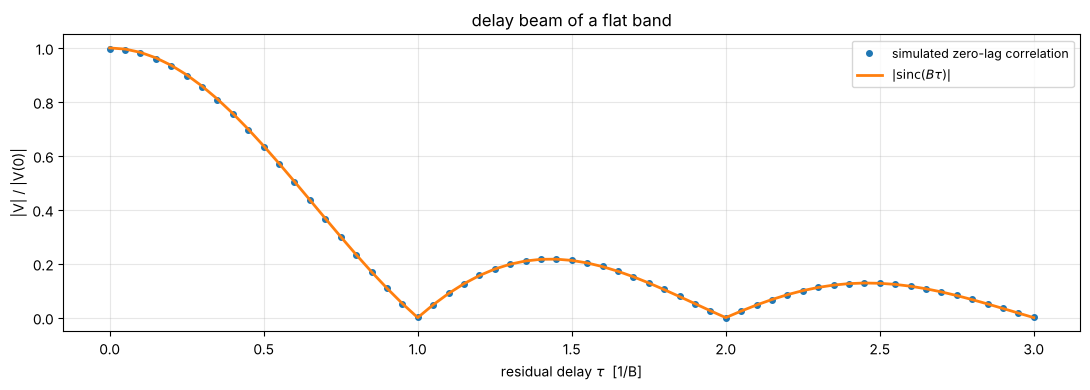

B210 band 2 MHz: first null at 500 ns; amplitude loss 10 % at 130 ns residual delay
geometric delay of the 11.5 km baseline: up to 38.4 µs = 77 times 1/B -> delay tracking is essential


In [9]:
taus = np.linspace(0, 3.0, 61)                             # residual delay in samples (1/B for B = f_s)
sim = []
for tau in taus:
    bb = fractional_delay(s, tau)
    sim.append(abs(np.mean(s * np.conj(bb))))
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(taus, sim, "o", ms=4, label="simulated zero-lag correlation")
ax.plot(taus, np.abs(np.sinc(taus)), lw=2, label=r"$|\mathrm{sinc}(B\tau)|$")
ax.set(xlabel=r"residual delay $\tau$  [1/B]", ylabel="|V| / |V(0)|", title="delay beam of a flat band")
ax.grid(alpha=0.3); ax.legend(fontsize=9); fig.tight_layout(); plt.show()
B = 2e6
print(f"B210 band {B / 1e6:.0f} MHz: first null at {1e9 / B:.0f} ns; amplitude loss 10 % at {1e9 * 0.26 / B:.0f} ns residual delay")
print("geometric delay of the 11.5 km baseline: up to", f"{11_500 / C_LIGHT * 1e6:.1f} µs = {11_500 / C_LIGHT * B:.0f} times 1/B -> delay tracking is essential")

## 8. Summary

| relation | statement | where in the chain |
|---|---|---|
| shift ↔ phase ramp | offset source → visibility phase; delay → phase slope across the band | notebooks 04, 05 |
| similarity | small structure ↔ long baselines | notebooks 01, 02 (baseline choice) |
| convolution theorem | dirty image = sky ∗ dirty beam; dish map = sky ∗ antenna pattern | notebooks 06, 07 |
| van Cittert–Zernike | V(u, v) = 2D FT of the brightness | every simulator |
| aperture autocorrelation | a dish is a low-pass filter up to D/λ | notebook 02, theory notebook of the teaching material |
| Wiener–Khinchin | cross spectrum = FT of the cross-correlation; XF ≡ FX | notebooks 03, 05 |
| flat band ↔ sinc | delay beam, first null at 1/B | notebooks 05, 08 |

## 9. Selector

Delay, number of lags/channels, correlation coefficient and whether the delay is removed before the FFT; *Run Interact* compares lag spectrum, XF and FX cross spectrum. (Needs a running kernel.)

In [10]:
import ipywidgets as widgets
from IPython.display import display

def run_corr(delay_samples, n_channels, rho, remove_delay, n_samples_log2):
    m = 2 ** n_samples_log2
    g = np.random.default_rng(5)
    s_ = (g.standard_normal(m) + 1j * g.standard_normal(m)) / np.sqrt(2)
    k = np.sqrt((1 - rho) / rho) if rho < 1 else 0.0          # receiver noise for the correlation coefficient rho (signal power 1)
    a_ = s_ + k * (g.standard_normal(m) + 1j * g.standard_normal(m)) / np.sqrt(2)
    b_ = fractional_delay(s_, delay_samples) + k * (g.standard_normal(m) + 1j * g.standard_normal(m)) / np.sqrt(2)
    if remove_delay:
        b_ = fractional_delay(b_, -delay_samples)
    lg, R_ = lag_correlation(a_, b_, n_channels)
    sx = xf_cross_spectrum(a_, b_, n_channels)
    ac_ = Accumulator.create(n_channels, "rect"); ac_.add(a_, b_)
    sf = ac_.visibility() / ac_.window_power
    ff = np.fft.fftshift(np.fft.fftfreq(n_channels))
    fig, axes = plt.subplots(1, 3, figsize=(19, 4.4))
    axes[0].stem(lg, np.abs(R_), basefmt=" "); axes[0].set(xlabel="lag  [samples]", ylabel="|R|", title="lag spectrum")
    axes[1].plot(ff, np.abs(sx), label="XF"); axes[1].plot(ff, np.abs(sf), "--", label="FX")
    axes[1].set(xlabel="frequency [cycles/sample]", ylabel="|S|", ylim=(0, 1.05 * max(np.abs(sx).max(), np.abs(sf).max())))
    axes[2].plot(ff, np.degrees(np.unwrap(np.angle(sx))), label="XF"); axes[2].plot(ff, np.degrees(np.unwrap(np.angle(sf))), "--", label="FX")
    axes[2].set(xlabel="frequency [cycles/sample]", ylabel="phase [deg]")
    for ax in axes: ax.grid(alpha=0.3)
    axes[1].legend(); axes[2].legend(); fig.tight_layout(); plt.show()
    print(f"mean |S|: XF {np.abs(sx).mean():.3f}, FX {np.abs(sf).mean():.3f} (correlated power 1, coefficient {rho:.2f}"
          f"{'' if remove_delay else f'; FX expected (N-τ)/N = {max(n_channels - abs(delay_samples), 0) / n_channels:.3f}'})")

display(widgets.interactive(
    run_corr, {"manual": True},
    delay_samples=widgets.FloatSlider(value=3.4, min=-30, max=30, step=0.1, description="delay [samples]"),
    n_channels=widgets.Dropdown(options=[16, 32, 64, 128, 256], value=64, description="lags / channels"),
    rho=widgets.FloatSlider(value=0.5, min=0.01, max=1.0, step=0.01, description="correlation"),
    remove_delay=widgets.Checkbox(value=False, description="remove delay before FX"),
    n_samples_log2=widgets.IntSlider(value=17, min=12, max=20, description="log2 samples"),
))

interactive(children=(FloatSlider(value=3.4, description='delay [samples]', max=30.0, min=-30.0), Dropdown(des…